# Demanda intermitente

Séries de demanda esparsa (vendas de itens lentos, peças de reposição) têm muitos zeros. Modelos de nível contínuo erram de dois jeitos nelas: preveem zero quase sempre (e acertam a maioria dos dias sem venda) ou espalham uma média que nunca acontece. Os métodos de demanda intermitente separam **quando** a demanda acontece de **quanto** ela vale.

| Método | Ideia |
|---|---|
| `croston_sba` | suaviza tamanhos e intervalos entre demandas; previsão `(1 − α/2) · z / p` |
| `tsb` | suaviza a probabilidade de demanda a cada período e o tamanho quando há demanda; decai quando a demanda para |
| `adida` | soma em blocos de `k` períodos (`k` = intervalo médio no treino), suaviza os blocos e divide por `k` |
| `imapa` | média do ADIDA nos níveis `1..k` |

Formam a família `intermittent`, fora da busca padrão. Este notebook mostra também por que a métrica importa: com muitos zeros, métricas de erro absoluto (MASE, MAE) premiam prever zero; a **RMSSE** (erro quadrático escalado) premia acertar o nível médio.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.adapters.intermittent import demand_profile
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def clean(ax, grid_axis="both"):
    """Recessive grid and axes; text in neutral ink."""
    ax.grid(axis=grid_axis, color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#52514e")


print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Dados

Série sintética diária: há venda em ~25% dos dias, e o tamanho de cada venda é 1 + Poisson(3). O perfil mostra a fração de zeros, o intervalo médio entre demandas (ADI) e o CV² dos tamanhos; ADI > 1,32 com CV² < 0,49 é o quadrante "intermitente" de Syntetos-Boylan.

{'zero_share': 0.736, 'adi': 3.697, 'cv2': 0.162}


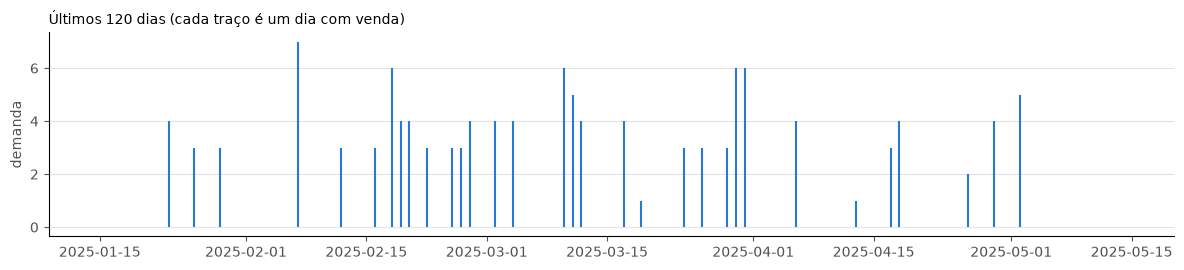

In [2]:
y = get_data("intermittent_daily", n=500)
print({name: round(value, 3) for name, value in demand_profile(y.to_numpy()).items()})
fig, ax = plt.subplots(figsize=(12, 2.8))
recent = y.iloc[-120:]
ax.vlines(recent.index, 0, recent, color="#2a78d6", linewidth=1.5)
ax.set_ylabel("demanda", color="#52514e")
ax.set_title("Últimos 120 dias (cada traço é um dia com venda)", loc="left", fontsize=10)
clean(ax, grid_axis="y")
fig.tight_layout()

## 2. Cada modelo nas mesmas origens

RMSSE, MASE e MAE médias em `V_select` (3 origens de 14 dias). Entram como referência o `naive`, a `historic_average` e o `window_average` de 28 dias.

In [3]:
exp = AutoHybridExperiment(fh=14, fold=3, session_id=42, metrics=["RMSSE", "MASE", "MAE"]).fit(y)
candidates = {
    "naive": {},
    "historic_average": {},
    "window_average": {"window": 28},
    "croston_sba": {},
    "tsb": {},
    "adida": {},
    "imapa": {},
}
rows = []
for name, params in candidates.items():
    frame = exp.create_model(name, **params).evaluation.to_frame()
    select = frame.loc[frame["layer"] == "select"]
    rows.append({"modelo": name, **select[["RMSSE", "MASE", "MAE"]].mean().to_dict()})
scores = pd.DataFrame(rows).set_index("modelo")
scores.round(3).sort_values("RMSSE")

,RMSSE,MASE,MAE
modelo,,,
historic_average,0.586,0.800,1.450
naive,0.597,0.564,1.024
adida,0.605,0.858,1.555
window_average,0.609,0.874,1.585
croston_sba,0.609,0.855,1.551
imapa,0.615,0.871,1.580
tsb,0.624,0.883,1.601


A ordem muda com a métrica. Pela MASE, o `naive` costuma ganhar: o último valor quase sempre é zero, e prever zero acerta os dias sem venda. Pela RMSSE, que pune desvios do nível médio, o `naive` cai. Nesta série a taxa de demanda é **constante** (sorteio independente a cada dia): a média do treino (`historic_average`) é a melhor previsão possível para erro quadrático, e os métodos intermitentes, que se adaptam ao passado recente, pagam por essa adaptação com variância.

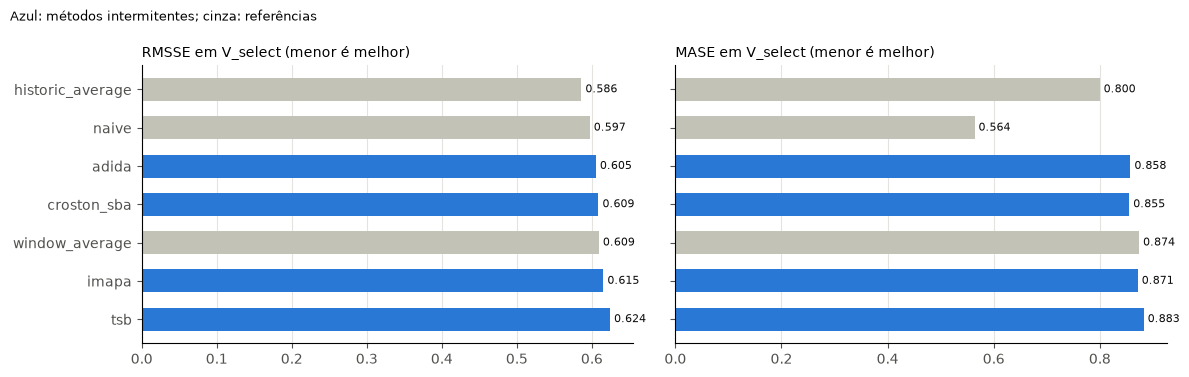

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
order = scores.sort_values("RMSSE").index[::-1]
intermittent = {"croston_sba", "tsb", "adida", "imapa"}
colors = ["#2a78d6" if name in intermittent else "#c3c2b7" for name in order]
for ax, metric in zip(axes, ["RMSSE", "MASE"], strict=True):
    values = scores.loc[order, metric]
    ax.barh(order, values, color=colors, height=0.6)
    for row, value in enumerate(values):
        ax.text(value, row, f" {value:.3f}", va="center", fontsize=8, color="#0b0b0b")
    ax.set_title(f"{metric} em V_select (menor é melhor)", loc="left", fontsize=10)
    clean(ax, grid_axis="x")
fig.suptitle("Azul: métodos intermitentes; cinza: referências", x=0.01, ha="left", fontsize=9)
fig.tight_layout()

## 3. Quando a taxa de demanda muda

Os métodos intermitentes existem para demanda cuja taxa muda. Abaixo, três séries (sementes 1 a 3) com venda em 10% dos dias nos primeiros 380 dias e em 40% nos últimos 120: as origens de validação caem depois da mudança. Mostramos as três sementes, não a mais favorável.

In [5]:
def shifted(seed):
    calm = get_data("intermittent_daily", n=380, seed=seed, probability=0.1)
    busy = get_data("intermittent_daily", n=120, seed=seed + 100, probability=0.4)
    index = pd.date_range("2024-01-01", periods=500, freq="D")
    return pd.Series(np.concatenate([calm, busy]), index=index, name="value")


def select_rmsse(experiment, name, params):
    frame = experiment.create_model(name, **params).evaluation.to_frame()
    return frame.loc[frame["layer"] == "select", "RMSSE"].mean()


rows = {}
for seed in (1, 2, 3):
    shift_exp = AutoHybridExperiment(fh=14, fold=3, session_id=42, metrics=["RMSSE"])
    shift_exp.fit(shifted(seed))
    rows[f"semente {seed}"] = {
        name: select_rmsse(shift_exp, name, params) for name, params in candidates.items()
    }
shift = pd.DataFrame(rows)
shift["média"] = shift.mean(axis=1)
shift.round(3).sort_values("média")

,semente 1,semente 2,semente 3,média
croston_sba,1.045,1.238,0.802,1.028
adida,1.034,1.259,0.799,1.031
imapa,1.060,1.230,0.803,1.031
window_average,1.095,1.205,0.803,1.034
tsb,1.134,1.224,0.796,1.051
historic_average,1.064,1.388,0.813,1.088
naive,1.678,1.557,0.931,1.389


## 4. TSB e Croston quando a demanda para

O Croston só atualiza quando há venda: se a demanda some, ele mantém a última taxa para sempre. O TSB atualiza a probabilidade todo dia e decai. Abaixo, os dois modelos ajustados no mesmo treino preveem a partir de contextos cada vez mais longos, em que os últimos dias são zeros (parâmetros congelados, sem reajuste: é assim que funcionam na variante B).

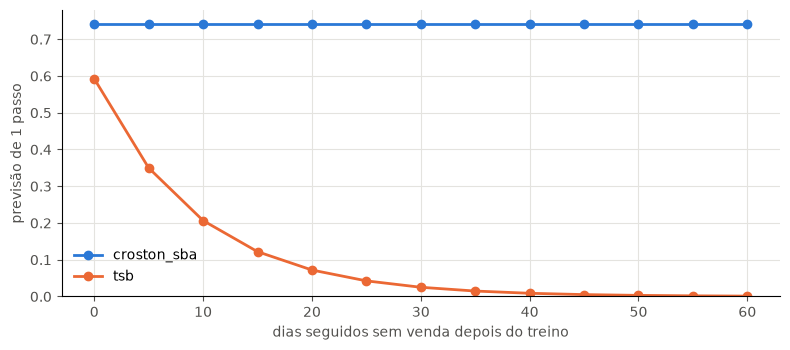

In [6]:
from autohybts.residuals.generation import local_context

train = y.to_numpy()[:400]
models = {name: exp.registry_.make_base(name).fit(train) for name in ["croston_sba", "tsb"]}
quiet = np.concatenate([train, np.zeros(60)])
days = np.arange(0, 61, 5)
fig, ax = plt.subplots(figsize=(8, 3.6))
for (name, model), color in zip(models.items(), ["#2a78d6", "#eb6834"], strict=True):
    path = [model.predict(1, local_context(quiet, 400 + d))[0] for d in days]
    ax.plot(days, path, marker="o", color=color, linewidth=2, label=name)
ax.set_xlabel("dias seguidos sem venda depois do treino", color="#52514e")
ax.set_ylabel("previsão de 1 passo", color="#52514e")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
clean(ax)
fig.tight_layout()

## 5. Busca e seleção com a família `intermittent`

Com algum método intermitente em `base_models`, a família entra na cadeia logo antes dos híbridos residuais e desafia o campeão pela mesma regra de aceite. A primeira métrica (`RMSSE`) ordena e decide.

In [7]:
search = AutoHybridExperiment(
    fh=14,
    fold=3,
    session_id=42,
    budget="small",
    metrics=["RMSSE", "MASE"],
    base_models=["naive", "seasonal_naive", "linear", "croston_sba", "tsb", "adida", "imapa"],
    correctors=["linear"],
    residual_windows=[14],
    alphas=[1.0],
).fit(y)
result = search.compare_models()
print("ordem da cadeia:", search.policy_.family_order)
print("campeão:", result.best.label)
result.decisions[
    [
        "family",
        "champion_before",
        "challenger",
        "accepted",
        "reason_codes",
        "median_gain",
        "win_rate",
    ]
]

ordem da cadeia: ('statistical', 'linear', 'kernel', 'tree', 'neural', 'intermittent', 'residual', 'decomposition', 'combination', 'dynamic')
campeão: linear(lags=7) + linear [w=14, alpha=1.0, historical_oof_1step]


,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate
0,statistical,tsb,naive,False,"(median_gain_below_threshold, win_rate_below_t...",-0.024991,0.333333
1,linear,tsb,linear,False,"(median_gain_below_threshold, win_rate_below_t...",-0.013341,0.333333
2,residual,tsb,linear-linear,True,"(accepted,)",0.048717,0.666667


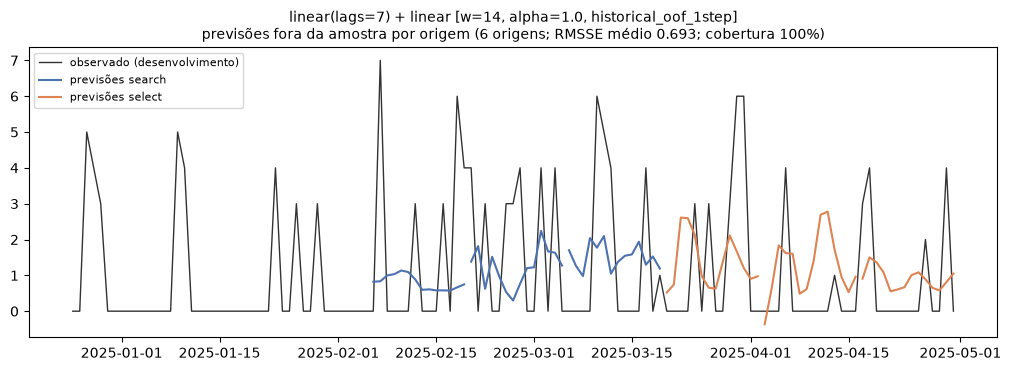

In [8]:
search.plot_model(result.best, "cv_forecasts")

## 6. Avaliação externa do campeão

Uma única leitura do teste selado, depois de congelar a escolha.

In [9]:
final = search.finalize_model(result.best)
search.evaluate_external(final).metrics.round(3)

,RMSSE,MASE
model,,
"linear(lags=7) + linear [w=14, alpha=1.0, historical_oof_1step]",0.536,0.671


## 7. Leitura

Nesta execução (500 dias, `fh=14`, 3 origens por camada):

* **A série é intermitente** pelo critério de Syntetos-Boylan: 74% de zeros, intervalo médio entre demandas 3,7 dias, CV² dos tamanhos 0,16.
* **A métrica decide quem vence.** Pela MASE, o `naive` ganha (0,56 contra 0,80–0,88 dos demais) porque prevê zero na maior parte dos dias. Pela RMSSE, o `naive` cai para o segundo lugar.
* **Com taxa constante, a média histórica é o melhor controle.** `historic_average` teve RMSSE 0,586; os métodos intermitentes ficaram entre 0,605 (`adida`) e 0,624 (`tsb`). Nenhum superou a média do treino: com demanda estacionária, adaptar-se ao passado recente só acrescenta variância.
* **Com mudança de taxa, eles se pagam, mas não sozinhos.** Nas três sementes com a taxa passando de 10% para 40%, `croston_sba`, `adida` e `imapa` ficaram com RMSSE média 1,03, contra 1,09 da `historic_average` e 1,39 do `naive`; a média móvel de 28 dias (1,03) empatou com eles. O ganho vem de esquecer o passado, que uma média em janela também faz.
* **TSB e Croston divergem quando a demanda para:** depois de 60 dias sem venda, o TSB prevê praticamente zero e o Croston mantém 0,74 por dia.
* **Na busca**, o TSB foi o melhor modelo isolado da busca e ficou como campeão inicial (nenhum outro isolado o superou em `V_select`); um híbrido `linear-linear` foi aceito com ganho mediano de 4,9% e 2 vitórias em 3 unidades. A série não tem estrutura além da taxa média, então esse aceite é provavelmente espúrio: com 3 unidades em `V_select`, a regra aceita estruturas sem ganho real com frequência (notebook 11).

Para demanda esparsa, compare sempre com `historic_average` e `window_average`, use a RMSSE (ou outra métrica de erro quadrático) para ordenar e aumente `fold` antes de confiar em um aceite.